In [153]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision.transforms import RandAugment
import torchvision.models as models
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import timm
import pandas as pd
import numpy as np
from tqdm.auto import tqdm
import os
import gc
from collections import Counter
import copy


**Data Processing**

In [154]:
from torch.utils.data import Dataset
from PIL import Image

class HAM10000FusionDataset(Dataset):
    def __init__(self, dataframe, img_dirs, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dirs = img_dirs 
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_name = row['image_id'] + ".jpg"

        for dir_path in self.img_dirs:
            image_path = os.path.join(dir_path, image_name)
            if os.path.exists(image_path):
                break
        else:
            raise FileNotFoundError(f"{image_name} not found in provided directories.")
        
        image = Image.open(image_path).convert('RGB')
        label = row['label']

        if self.transform:
            image = self.transform(image)

        # Load metadata
        meta = torch.tensor(row['meta'], dtype=torch.float32)

        # Load label
        label = torch.tensor(row['label'], dtype=torch.long)

        return image, meta, label
    
class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, img_dirs, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_dirs = img_dirs  # List of directories
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_name = row['image_id'] + ".jpg"

        # Look for the image in both directories
        for dir_path in self.img_dirs:
            image_path = os.path.join(dir_path, image_name)
            if os.path.exists(image_path):
                break
        else:
            raise FileNotFoundError(f"{image_name} not found in provided directories.")

        image = Image.open(image_path).convert('RGB')
        label = row['label']

        if self.transform:
            image = self.transform(image)

        return image, label

In [155]:
metadata_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/HAM10K/HAM10000_metadata.csv"

# Load metadata
df = pd.read_csv(metadata_path)

# Drop samples with missing values in key metadata fields
df = df.dropna(subset=['age', 'sex', 'localization'])

# Normalize age
scaler = MinMaxScaler()
df['age_norm'] = scaler.fit_transform(df[['age']])

# One-hot encode categorical variables
df = pd.get_dummies(df, columns=['sex', 'localization'], drop_first=False)

# Define metadata feature columns
meta_features = ['age_norm'] + [col for col in df.columns if col.startswith('sex_') or col.startswith('localization_')]
df['meta'] = df[meta_features].values.tolist()

# Encode labels
label_map = {label: i for i, label in enumerate(df['dx'].unique())}
df['label'] = df['dx'].map(label_map)

img_dirs = [
    "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/HAM10K/HAM10000_images_part_1",
    "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/HAM10K/HAM10000_images_part_2"
]

def find_image_path(image_id):
    for dir_path in img_dirs:
        path = os.path.join(dir_path, f"{image_id}.jpg")
        if os.path.exists(path):
            return path
    return None

df['image_path'] = df['image_id'].apply(find_image_path)

unique_ids = df['lesion_id'].unique()
train_ids, temp_ids = train_test_split(unique_ids, test_size=0.2, random_state=42)
val_ids, test_ids = train_test_split(temp_ids, test_size=0.5, random_state=42)

train_df = df[df['lesion_id'].isin(train_ids)]
val_df = df[df['lesion_id'].isin(val_ids)]
test_df = df[df['lesion_id'].isin(test_ids)]

In [ ]:
# train_transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.RandomHorizontalFlip(),
#     transforms.RandomVerticalFlip(),
#     transforms.RandomRotation(30),
#     transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
#     transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406],
#                          std=[0.229, 0.224, 0.225]),
#     transforms.RandomErasing(p=0.5, scale=(0.02, 0.25), ratio=(0.3, 3.3), value=0)
# ])

# val_transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406],
#                          std=[0.229, 0.224, 0.225])
# ])

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(size=224, scale=(0.8, 1.0)),
    RandAugment(num_ops=2, magnitude=9),  # RandAugment
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.25), ratio=(0.3, 3.3), value=0)  # Cutout
])

# train_transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     RandAugment(num_ops=2, magnitude=9),  # RandAugment
#     transforms.ToTensor(),
#     transforms.Normalize(mean=[0.485, 0.456, 0.406],
#                          std=[0.229, 0.224, 0.225])
# ])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_dataset = HAM10000Dataset(train_df, img_dirs, transform=train_transform)
val_dataset = HAM10000Dataset(val_df, img_dirs, transform=val_transform)
test_dataset = HAM10000Dataset(test_df, img_dirs, transform=val_transform)

# label_counts = train_df['label'].value_counts().sort_index().values
# class_weights = 1. / label_counts
# class_weights = class_weights / class_weights.sum() * len(class_weights)  # Normalize

# label_to_weight = {label: class_weights[i] for i, label in enumerate(sorted(train_df['label'].unique()))}
# sample_weights = train_df['label'].map(label_to_weight).values

# sampler = WeightedRandomSampler(
#     weights=sample_weights,
#     num_samples=len(sample_weights),
#     replacement=True
# )

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

meta_input_dim = len(meta_features)


In [ ]:
from collections import Counter

# Count how many samples of each class appear after sampling
label_counter = Counter()

for images, labels in train_loader:
    labels = labels.cpu().numpy()
    label_counter.update(labels)

# Print counts
for label, count in sorted(label_counter.items()):
    print(f"Class {label}: {count} samples")


In [5]:
labels = [label for _, label in train_loader.dataset]
class_counts = Counter(labels)
num_classes = len(class_counts)
total_samples = sum(class_counts.values())

# Compute inverse frequency weights
class_weights = [total_samples / class_counts[i] for i in range(num_classes)]
class_weights = torch.tensor(class_weights, dtype=torch.float).to("cuda")

**Training:**

In [6]:
device = torch.device("cuda")
criterion = torch.nn.CrossEntropyLoss()
criterion_weighted = torch.nn.CrossEntropyLoss(weight=class_weights)
learning_rate = 1e-4
weight_decay = 1e-4
num_classes = 7

**Training Loop**

In [7]:
def train_model(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)

        # ---------- Training ----------
        model.train()
        train_loss = 0.0
        train_correct = 0

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_correct += (outputs.argmax(1) == labels).sum().item()

        train_acc = train_correct / len(train_loader.dataset)

        # ---------- Validation ----------
        model.eval()
        val_loss = 0.0
        val_correct = 0

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_acc = val_correct / len(val_loader.dataset)

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f}, Val   Acc: {val_acc:.4f}")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = model.state_dict()
            print("Best model updated")

            # Save checkpoint
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

    model.load_state_dict(best_model_wts)
    return model

**Freeze Training Loop**

In [8]:
def train_model_freeze(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path, freeze_epochs=5):
    model.to(device)

    # Phase 1: Freeze base model (only train classifier)
    for name, param in model.named_parameters():
        if "classif" not in name and "classifier" not in name and "fc" not in name:  # classifier name varies
            param.requires_grad = False

    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate, weight_decay=weight_decay)
    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_acc = running_corrects.double() / len(train_loader.dataset)

        # Validation
        model.eval()
        val_corrects = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                val_corrects += torch.sum(preds == labels.data)

        val_acc = val_corrects.double() / len(val_loader.dataset)

        print(f"Epoch {epoch+1}/{num_epochs} - Train Acc: {epoch_acc:.4f} - Val Acc: {val_acc:.4f}")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)
            print("Best model updated")

        # Phase 2: Unfreeze base model after `freeze_epochs`
        if epoch + 1 == freeze_epochs:
            print("Unfreezing base model for fine-tuning")
            for param in model.parameters():
                param.requires_grad = True
            optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate / 10, weight_decay=weight_decay)

    model.load_state_dict(best_model_wts)
    return model

**Training With Learning Rate Scheduler**

In [9]:
from torch.optim.lr_scheduler import StepLR

def train_model_lr(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  # decay LR every 5 epochs

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)

        # ---------- Training ----------
        model.train()
        train_loss = 0.0
        train_correct = 0

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_correct += (outputs.argmax(1) == labels).sum().item()

        train_acc = train_correct / len(train_loader.dataset)

        # ---------- Validation ----------
        model.eval()
        val_loss = 0.0
        val_correct = 0

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_acc = val_correct / len(val_loader.dataset)

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f}, Val   Acc: {val_acc:.4f}")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = model.state_dict()
            print("Best model updated")

            # Save checkpoint
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        scheduler.step()

    model.load_state_dict(best_model_wts)
    return model


**Training With Scheduler + Freeze**

In [10]:
from torch.optim.lr_scheduler import StepLR

def train_model_lr_freeze(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    for name, param in model.named_parameters():
        if "classif" not in name and "classifier" not in name and "fc" not in name:  # classifier name varies
            param.requires_grad = False

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  # decay LR every 5 epochs

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)

        # ---------- Training ----------
        model.train()
        train_loss = 0.0
        train_correct = 0

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_correct += (outputs.argmax(1) == labels).sum().item()

        train_acc = train_correct / len(train_loader.dataset)

        # ---------- Validation ----------
        model.eval()
        val_loss = 0.0
        val_correct = 0

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_acc = val_correct / len(val_loader.dataset)

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f}, Val   Acc: {val_acc:.4f}")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = model.state_dict()
            print("Best model updated")

            # Save checkpoint
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        scheduler.step()

    model.load_state_dict(best_model_wts)
    return model

In [11]:
def train_model_lr_unfreeze(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    # --------- Freeze all but classifier ---------
    for name, param in model.named_parameters():
        if "classif" not in name and "classifier" not in name and "fc" not in name:  # classifier name varies
            param.requires_grad = False

    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), 
                                 lr=learning_rate, weight_decay=weight_decay)
    scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  # decay LR every 5 epochs

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        print("-" * 30)

        # --------- Unfreeze backbone after 15 epochs ---------
        if epoch == 15:
            print("Unfreezing backbone for fine-tuning...")
            for param in model.parameters():
                param.requires_grad = True

            # Reinitialize optimizer with smaller LR for fine-tuning
            optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate * 0.1, weight_decay=weight_decay)
            scheduler = StepLR(optimizer, step_size=5, gamma=0.1)

        # ---------- Training ----------
        model.train()
        train_loss = 0.0
        train_correct = 0

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            train_correct += (outputs.argmax(1) == labels).sum().item()

        train_acc = train_correct / len(train_loader.dataset)

        # ---------- Validation ----------
        model.eval()
        val_loss = 0.0
        val_correct = 0

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_acc = val_correct / len(val_loader.dataset)

        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
        print(f"Val   Loss: {val_loss:.4f}, Val   Acc: {val_acc:.4f}")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = model.state_dict()
            print("Best model updated")

            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        scheduler.step()

    model.load_state_dict(best_model_wts)
    return model

**BACC Evaluation**

In [12]:
def train_model_bacc(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    # scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend(preds.cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
        print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        y_true_val, y_pred_val = [], []

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, preds = torch.max(outputs, 1)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend(preds.cpu().numpy())

        val_loss /= len(val_loader)
        val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)

        if val_bacc > best_val_acc:
            best_val_acc = val_bacc
            best_model_wts = model.state_dict()
            print("Best model updated")

            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        print(f"Val Loss: {val_loss:.4f}, Val BACC: {val_bacc:.4f}")

    model.load_state_dict(best_model_wts)
    return model

In [13]:
# def train_model_bacc_lr(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
#     model = model.to(device)
#     best_val_acc = 0.0
#     best_model_wts = model.state_dict()

#     optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
#     scheduler = StepLR(optimizer, step_size=5, gamma=0.1)  # reduce LR every 5 epochs by factor of 0.1

#     for epoch in range(num_epochs):
#         print(f"\nEpoch {epoch+1}/{num_epochs}")

#         # --- TRAIN ---
#         model.train()
#         running_loss = 0.0
#         y_true_train, y_pred_train = [], []

#         for images, labels in tqdm(train_loader, desc="Training"):
#             images, labels = images.to(device), labels.to(device)

#             optimizer.zero_grad()
#             outputs = model(images)
#             loss = criterion(outputs, labels)
#             loss.backward()
#             optimizer.step()

#             running_loss += loss.item()

#             _, preds = torch.max(outputs, 1)
#             y_true_train.extend(labels.cpu().numpy())
#             y_pred_train.extend(preds.cpu().numpy())

#         train_loss = running_loss / len(train_loader)
#         train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
#         print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

#         # --- VALIDATION ---
#         model.eval()
#         val_loss = 0.0
#         y_true_val, y_pred_val = [], []

#         with torch.no_grad():
#             for images, labels in tqdm(val_loader, desc="Validation"):
#                 images, labels = images.to(device), labels.to(device)
#                 outputs = model(images)
#                 loss = criterion(outputs, labels)
#                 val_loss += loss.item()

#                 _, preds = torch.max(outputs, 1)
#                 y_true_val.extend(labels.cpu().numpy())
#                 y_pred_val.extend(preds.cpu().numpy())

#         val_loss /= len(val_loader)
#         val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)

#         if val_bacc > best_val_acc:
#             best_val_acc = val_bacc
#             best_model_wts = model.state_dict()
#             print("Best model updated")

#             torch.save({
#                 'epoch': epoch + 1,
#                 'model_state_dict': best_model_wts,
#                 'optimizer_state_dict': optimizer.state_dict(),
#                 'val_acc': best_val_acc
#             }, checkpoint_path)

#         print(f"Val Loss: {val_loss:.4f}, Val BACC: {val_bacc:.4f}")
#         print(f"Learning Rate: {scheduler.get_last_lr()[0]:.6f}")

#         # Step scheduler at the end of each epoch
#         scheduler.step()

#     # Load best model weights
#     model.load_state_dict(best_model_wts)
#     return model

def train_model_bacc_lr(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    # Drop LR at specific epochs (milestones)
    scheduler = MultiStepLR(optimizer, milestones=[10, 20, 30], gamma=0.1)

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")

        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend(preds.cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
        print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        y_true_val, y_pred_val = [], []

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, preds = torch.max(outputs, 1)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend(preds.cpu().numpy())

        val_loss /= len(val_loader)
        val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)

        if val_bacc > best_val_acc:
            best_val_acc = val_bacc
            best_model_wts = model.state_dict()
            print("Best model updated")

            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        print(f"Val Loss: {val_loss:.4f}, Val BACC: {val_bacc:.4f}")
        print(f"Learning Rate: {scheduler.get_last_lr()[0]:.6f}")

        # Step scheduler at the end of each epoch
        scheduler.step()

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model

In [10]:
def train_model_bacc_freeze(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    for name, param in model.named_parameters():
        if "classif" not in name and "classifier" not in name and "fc" not in name:  # classifier name varies
            param.requires_grad = False

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = MultiStepLR(optimizer, milestones=[10, 20, 30], gamma=0.1)

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")

        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend(preds.cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
        print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        y_true_val, y_pred_val = [], []

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, preds = torch.max(outputs, 1)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend(preds.cpu().numpy())

        val_loss /= len(val_loader)
        val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)

        if val_bacc > best_val_acc:
            best_val_acc = val_bacc
            best_model_wts = model.state_dict()
            print("Best model updated")

            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        print(f"Val Loss: {val_loss:.4f}, Val BACC: {val_bacc:.4f}")

        # Step scheduler at the end of each epoch
        scheduler.step()

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model

In [7]:
from sklearn.metrics import balanced_accuracy_score
from torch.optim.lr_scheduler import MultiStepLR


def train_model_bacc_unfreeze(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    # --- Freeze all layers except classifier ---
    for name, param in model.named_parameters():
        if "classif" not in name and "classifier" not in name and "fc" not in name:
            param.requires_grad = False

    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), 
                                 lr=learning_rate, weight_decay=weight_decay)
    scheduler = MultiStepLR(optimizer, milestones=[20], gamma=0.1)

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")

        # --- Unfreeze rest of the model at the specified epoch ---
        if epoch == 15:
            print(f"Unfreezing all layers at epoch {epoch+1}")
            for param in model.parameters():
                param.requires_grad = True

            optimizer = torch.optim.Adam(model.parameters(), 
                                         lr=scheduler.get_last_lr()[0],  # Lower LR after unfreezing
                                         weight_decay=weight_decay)
            scheduler = MultiStepLR(optimizer, milestones=[35, 50], gamma=0.1)

        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []

        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend(preds.cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
        print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        y_true_val, y_pred_val = [], []

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, preds = torch.max(outputs, 1)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend(preds.cpu().numpy())

        val_loss /= len(val_loader)
        val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)

        if val_bacc > best_val_acc:
            best_val_acc = val_bacc
            best_model_wts = model.state_dict()
            print("Best model updated")

            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        print(f"Val Loss: {val_loss:.4f}, Val BACC: {val_bacc:.4f}")

        # Step scheduler at the end of each epoch
        scheduler.step()

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model

**Models for Ensemble:**

**EfficientNet-B2**

In [34]:
def get_efficientnet_b0(num_classes):
    model = models.efficientnet_b0(weights='EfficientNet_B0_Weights.DEFAULT')
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

In [35]:
def get_efficientnet_b2(num_classes):
    model = models.efficientnet_b2(weights='EfficientNet_B2_Weights.DEFAULT')
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

In [36]:
def get_efficientnet_b3(num_classes):
    model = models.efficientnet_b3(weights='EfficientNet_B3_Weights.DEFAULT')
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

In [37]:
def get_efficientnet_b4(num_classes):
    model = models.efficientnet_b4(weights='EfficientNet_B4_Weights.DEFAULT')
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

**EfficientNet-B7**

In [38]:
def get_efficientnet_b7(num_classes):
    model = models.efficientnet_b7(weights='EfficientNet_B7_Weights.DEFAULT')
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)
    return model

**Base EffNet 2**

In [27]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights.pth"
effnet_b2 = get_efficientnet_b2(num_classes=num_classes)
effnet_b2 = train_model(effnet_b2, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=25, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/25
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.10it/s]


Train Loss: 83.2122, Train Acc: 0.7209
Val   Loss: 18.5509, Val   Acc: 0.6973
Best model updated

Epoch 2/25
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.14it/s]


Train Loss: 51.6499, Train Acc: 0.8254
Val   Loss: 18.9784, Val   Acc: 0.7033
Best model updated

Epoch 3/25
------------------------------


...

Train Loss: 16.0028, Train Acc: 0.9460
Val   Loss: 22.4850, Val   Acc: 0.7950

Epoch 24/25
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.09it/s]


Train Loss: 15.4352, Train Acc: 0.9497
Val   Loss: 19.0841, Val   Acc: 0.7837

Epoch 25/25
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.06it/s]

Train Loss: 13.0403, Train Acc: 0.9560
Val   Loss: 20.9341, Val   Acc: 0.7810


In [ ]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights_2.pth"
effnet_b2_2 = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_2 = train_model(effnet_b2_2, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=25, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b2_path)

**Scheduler EffNet**

In [30]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights_LR.pth"
effnet_b2_lr = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_lr = train_model_lr(effnet_b2_lr, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=20, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.16it/s]


Train Loss: 86.1363, Train Acc: 0.7124
Val   Loss: 21.7043, Val   Acc: 0.6731
Best model updated

Epoch 2/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.09it/s]


Train Loss: 50.8132, Train Acc: 0.8279
Val   Loss: 19.4373, Val   Acc: 0.7019
Best model updated

Epoch 3/20
------------------------------


...

Train Loss: 10.3762, Train Acc: 0.9645
Val   Loss: 15.0489, Val   Acc: 0.8359
Best model updated

Epoch 19/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.10it/s]


Train Loss: 10.1418, Train Acc: 0.9652
Val   Loss: 15.1620, Val   Acc: 0.8319

Epoch 20/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.13it/s]

Train Loss: 11.1313, Train Acc: 0.9649
Val   Loss: 15.0347, Val   Acc: 0.8299


In [35]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights_LR.pth"
effnet_b2_lr = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_lr = train_model_lr(effnet_b2_lr, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=30, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.12it/s]


Train Loss: 84.3793, Train Acc: 0.7216
Val   Loss: 20.4009, Val   Acc: 0.6792
Best model updated

Epoch 2/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.12it/s]


Train Loss: 54.2842, Train Acc: 0.8167
Val   Loss: 17.8542, Val   Acc: 0.7589
Best model updated

Epoch 3/30
------------------------------


...

Train Loss: 9.7290, Train Acc: 0.9690
Val   Loss: 15.6711, Val   Acc: 0.8372
Best model updated

Epoch 29/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.94it/s]


Train Loss: 10.2739, Train Acc: 0.9651
Val   Loss: 16.1366, Val   Acc: 0.8232

Epoch 30/30
------------------------------


Validation: 100%|██████████| 24/24 [00:13<00:00,  1.82it/s]

Train Loss: 9.7167, Train Acc: 0.9654
Val   Loss: 16.0373, Val   Acc: 0.8279


**EffNet2 Scheduler With CutOut**

In [24]:
# With CutOut
effnet_b2_path_2 = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights_LR_2.pth"
effnet_b2_lr_2 = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_lr_2 = train_model_lr(effnet_b2_lr_2, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=30, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path_2)


Epoch 1/30
------------------------------


Validation: 100%|██████████| 24/24 [00:15<00:00,  1.55it/s]


Train Loss: 91.9400, Train Acc: 0.6813
Val   Loss: 17.1205, Val   Acc: 0.7495
Best model updated

Epoch 2/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.18it/s]


Train Loss: 57.3275, Train Acc: 0.8016
Val   Loss: 19.0879, Val   Acc: 0.7167

Epoch 3/30
------------------------------


...

Train Loss: 16.8188, Train Acc: 0.9418
Val   Loss: 15.7636, Val   Acc: 0.8225

Epoch 29/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.02it/s]


Train Loss: 16.1575, Train Acc: 0.9460
Val   Loss: 15.4172, Val   Acc: 0.8285

Epoch 30/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.09it/s]

Train Loss: 16.2840, Train Acc: 0.9477
Val   Loss: 15.7522, Val   Acc: 0.8225


**EffNet Scheduler + Freeze**

In [39]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights_Freeze_LR.pth"
effnet_b2_freeze_lr = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_freeze_lr = train_model_lr_freeze(effnet_b2_freeze_lr, train_loader, val_loader, criterion, num_epochs=30, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/30
------------------------------


Validation: 100%|██████████| 24/24 [00:20<00:00,  1.18it/s]


Train Loss: 116.8015, Train Acc: 0.6191
Val   Loss: 18.5310, Val   Acc: 0.7013
Best model updated

Epoch 2/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.76it/s]


Train Loss: 67.9870, Train Acc: 0.7644
Val   Loss: 15.9189, Val   Acc: 0.7589
Best model updated

Epoch 3/30
------------------------------


...

Train Loss: 35.4249, Train Acc: 0.8761
Val   Loss: 14.9819, Val   Acc: 0.7843

Epoch 29/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.84it/s]


Train Loss: 33.1018, Train Acc: 0.8879
Val   Loss: 15.1783, Val   Acc: 0.7796

Epoch 30/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.96it/s]

Train Loss: 34.4925, Train Acc: 0.8810
Val   Loss: 15.0760, Val   Acc: 0.7823


**EffNet2 Scheduler, Freeze, Unfreeze**

In [43]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights_Unfreeze_LR.pth"
effnet_b2_unfreeze_lr = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_unfreeze_lr = train_model_lr_unfreeze(effnet_b2_unfreeze_lr, train_loader, val_loader, criterion, num_epochs=40, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/40
------------------------------


Validation: 100%|██████████| 24/24 [00:15<00:00,  1.60it/s]


Train Loss: 118.8472, Train Acc: 0.6062
Val   Loss: 17.1799, Val   Acc: 0.7549
Best model updated

Epoch 2/40
------------------------------


Validation: 100%|██████████| 24/24 [00:12<00:00,  1.89it/s]


Train Loss: 70.3419, Train Acc: 0.7617
Val   Loss: 16.0113, Val   Acc: 0.7549

Epoch 3/40
------------------------------


...

Train Loss: 17.2629, Train Acc: 0.9424
Val   Loss: 14.6029, Val   Acc: 0.8198

Epoch 39/40
------------------------------


Validation: 100%|██████████| 24/24 [00:11<00:00,  2.08it/s]


Train Loss: 17.1332, Train Acc: 0.9415
Val   Loss: 14.6492, Val   Acc: 0.8198

Epoch 40/40
------------------------------


Validation: 100%|██████████| 24/24 [00:11<00:00,  2.14it/s]

Train Loss: 18.5061, Train Acc: 0.9357
Val   Loss: 14.5142, Val   Acc: 0.8158


**Freeze EffNet**

In [24]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/EffNet2_Weights_Freeze.pth"
effnet_b2_freeze = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_freeze = train_model_freeze(effnet_b2_freeze, train_loader, val_loader, criterion, num_epochs=20, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=effnet_b2_path, freeze_epochs=5)

Epoch 1/20 - Train Acc: 0.3096 - Val Acc: 0.4829
Best model updated
Epoch 2/20 - Train Acc: 0.5543 - Val Acc: 0.6175
Best model updated
Epoch 3/20 - Train Acc: 0.6310 - Val Acc: 0.6390
Best model updated
Epoch 4/20 - Train Acc: 0.6855 - Val Acc: 0.6624
Best model updated
Epoch 5/20 - Train Acc: 0.7318 - Val Acc: 0.6872
Best model updated
Unfreezing base model for fine-tuning
Epoch 6/20 - Train Acc: 0.7520 - Val Acc: 0.6865
Epoch 7/20 - Train Acc: 0.7673 - Val Acc: 0.6993
Best model updated
Epoch 8/20 - Train Acc: 0.7789 - Val Acc: 0.6999
Best model updated
Epoch 9/20 - Train Acc: 0.7847 - Val Acc: 0.7053
Best model updated
Epoch 10/20 - Train Acc: 0.8022 - Val Acc: 0.7173
Best model updated
Epoch 11/20 - Train Acc: 0.8127 - Val Acc: 0.7334
Best model updated
Epoch 12/20 - Train Acc: 0.8153 - Val Acc: 0.7468
Best model updated
Epoch 13/20 - Train Acc: 0.8249 - Val Acc: 0.7361
Epoch 14/20 - Train Acc: 0.8351 - Val Acc: 0.7374
Epoch 15/20 - Train Acc: 0.8381 - Val Acc: 0.7475
Best model u

**BACC Training**

**EffNet-2: Vanilla Training**

In [48]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/BACC/EffNet2_Weights_BACC"
effnet_b2_bacc = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_bacc = train_model_bacc(effnet_b2_bacc, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=40, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/40


Training: 100%|██████████| 125/125 [00:58<00:00,  2.14it/s]


Train Loss: 0.7355, Train BACC: 0.4228


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.12it/s]


Best model updated
Val Loss: 0.7122, Val BACC: 0.4760

Epoch 2/40


...

Val Loss: 1.1041, Val BACC: 0.6519

Epoch 40/40


Training: 100%|██████████| 125/125 [00:58<00:00,  2.13it/s]


Train Loss: 0.0920, Train BACC: 0.9444


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.16it/s]

Val Loss: 0.9851, Val BACC: 0.6342


In [14]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/BACC/EffNet2_Weights_BACC_LR"
effnet_b2_bacc_lr = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_bacc_lr = train_model_bacc_lr(effnet_b2_bacc_lr, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=40, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/40


Training: 100%|██████████| 125/125 [00:59<00:00,  2.11it/s]


Train Loss: 1.3893, Train BACC: 0.4940


Validation: 100%|██████████| 16/16 [00:05<00:00,  2.99it/s]


Best model updated
Val Loss: 1.0403, Val BACC: 0.5955
Learning Rate: 0.001000

Epoch 2/40


...

Val Loss: 0.7858, Val BACC: 0.6892
Learning Rate: 0.000001

Epoch 40/40


Training: 100%|██████████| 125/125 [01:15<00:00,  1.66it/s]


Train Loss: 0.1383, Train BACC: 0.9545


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.07it/s]

Val Loss: 0.8320, Val BACC: 0.6865
Learning Rate: 0.000001


In [ ]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/BACC/EffNet2_Weights_BACC_Freeze"
effnet_b2_bacc_freeze = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_bacc_freeze = train_model_bacc_freeze(effnet_b2_bacc_freeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=40, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)

In [19]:
effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/BACC/EffNet2_Weights_BACC_Unfreeze"
effnet_b2_bacc_unfreeze = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_bacc_unfreeze = train_model_bacc_unfreeze(effnet_b2_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=40, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/40


Training: 100%|██████████| 63/63 [03:41<00:00,  3.52s/it]


Train Loss: 1.5404, Train BACC: 0.4149


Validation: 100%|██████████| 8/8 [00:12<00:00,  1.62s/it]


Best model updated
Val Loss: 0.9968, Val BACC: 0.6068

Epoch 2/40


...

Val Loss: 0.6553, Val BACC: 0.7423

Epoch 40/40


Training: 100%|██████████| 63/63 [05:53<00:00,  5.62s/it]


Train Loss: 0.2620, Train BACC: 0.9148


Validation: 100%|██████████| 8/8 [00:09<00:00,  1.21s/it]

Val Loss: 0.6460, Val BACC: 0.7724


In [ ]:
gc.collect()
torch.cuda.empty_cache()

# 79.13

effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/BACC/EffNet2_Weights_BACC_Unfreeze2"
effnet_b2_bacc_unfreeze_2 = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_bacc_unfreeze_2 = train_model_bacc_unfreeze(effnet_b2_bacc_unfreeze_2, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/70


Training: 100%|██████████| 125/125 [00:55<00:00,  2.25it/s]


Train Loss: 1.4716, Train BACC: 0.4519


Validation: 100%|██████████| 16/16 [00:04<00:00,  3.23it/s]


Best model updated
Val Loss: 0.8541, Val BACC: 0.6376

Epoch 2/70


...

Val Loss: 0.6413, Val BACC: 0.7461

Epoch 70/70


Training: 100%|██████████| 125/125 [00:59<00:00,  2.10it/s]


Train Loss: 0.2979, Train BACC: 0.9024


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.18it/s]

Val Loss: 0.5686, Val BACC: 0.7708


In [ ]:
gc.collect()
torch.cuda.empty_cache()

# 76

effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/BACC/EffNet2_Weights_BACC_Unfreeze3"
effnet_b2_bacc_unfreeze_3 = get_efficientnet_b2(num_classes=num_classes)
effnet_b2_bacc_unfreeze_3 = train_model_bacc_unfreeze(effnet_b2_bacc_unfreeze_3, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b2_path)


Epoch 1/70


Training: 100%|██████████| 125/125 [00:55<00:00,  2.25it/s]


Train Loss: 1.4840, Train BACC: 0.4370


Validation: 100%|██████████| 16/16 [00:04<00:00,  3.36it/s]


Best model updated
Val Loss: 0.8905, Val BACC: 0.6082

Epoch 2/70


...

Val Loss: 0.8207, Val BACC: 0.6832

Epoch 70/70


Training: 100%|██████████| 125/125 [01:01<00:00,  2.05it/s]


Train Loss: 0.1114, Train BACC: 0.9644


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.08it/s]

Val Loss: 0.8076, Val BACC: 0.6856


**EffNet-3 BACC**

In [25]:
gc.collect()
torch.cuda.empty_cache()

# 76

effnet_b3_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet3 Weights/BACC/EffNet3_Weights_BACC_Unfreeze"
effnet_b3_bacc_unfreeze = get_efficientnet_b3(num_classes=num_classes)
effnet_b3_bacc_unfreeze = train_model_bacc_unfreeze(effnet_b3_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b3_path)


Epoch 1/70


Training: 100%|██████████| 125/125 [01:02<00:00,  2.00it/s]


Train Loss: 1.5278, Train BACC: 0.4065


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.09it/s]


Best model updated
Val Loss: 0.9658, Val BACC: 0.6354

Epoch 2/70


...

Val Loss: 0.8609, Val BACC: 0.6629

Epoch 70/70


Training: 100%|██████████| 125/125 [01:07<00:00,  1.85it/s]


Train Loss: 0.0991, Train BACC: 0.9677


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.03it/s]


Val Loss: 0.7831, Val BACC: 0.6807


In [ ]:
gc.collect()
torch.cuda.empty_cache()

#78

effnet_b3_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet3 Weights/BACC/EffNet3_Weights_BACC_Unfreeze2"
effnet_b3_bacc_unfreeze2 = get_efficientnet_b3(num_classes=num_classes)
effnet_b3_bacc_unfreeze2 = train_model_bacc_unfreeze(effnet_b3_bacc_unfreeze2, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b3_path)


Epoch 1/70


Training: 100%|██████████| 125/125 [01:00<00:00,  2.05it/s]


Train Loss: 1.5353, Train BACC: 0.4230


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.11it/s]


Best model updated
Val Loss: 0.9034, Val BACC: 0.6488

Epoch 2/70


...

Val Loss: 0.8622, Val BACC: 0.6873

Epoch 70/70


Training: 100%|██████████| 125/125 [01:16<00:00,  1.62it/s]


Train Loss: 0.1798, Train BACC: 0.9513


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.43it/s]

Val Loss: 0.8794, Val BACC: 0.6614


**EffNet-4 BACC**

In [ ]:
gc.collect()
torch.cuda.empty_cache()

effnet_b4_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet4 Weights/BACC/EffNet4_Weights_BACC_Unfreeze"
effnet_b4_bacc_unfreeze = get_efficientnet_b4(num_classes=num_classes)
effnet_b4_bacc_unfreeze = train_model_bacc_unfreeze(effnet_b4_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b4_path)

**EffNet-0 BACC**

In [ ]:
gc.collect()
torch.cuda.empty_cache()

# 77

effnet_b0_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet0 Weights/BACC/EffNet0_Weights_BACC_Unfreeze"
effnet_b0_bacc_unfreeze = get_efficientnet_b0(num_classes=num_classes)
effnet_b0_bacc_unfreeze = train_model_bacc_unfreeze(effnet_b0_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b0_path)


Epoch 1/70


Training: 100%|██████████| 125/125 [00:51<00:00,  2.42it/s]


Train Loss: 1.4936, Train BACC: 0.4481


Validation: 100%|██████████| 16/16 [00:05<00:00,  2.80it/s]


Best model updated
Val Loss: 1.0636, Val BACC: 0.6492

Epoch 2/70


...

Val Loss: 0.7459, Val BACC: 0.7185

Epoch 70/70


Training: 100%|██████████| 125/125 [00:51<00:00,  2.43it/s]


Train Loss: 0.1341, Train BACC: 0.9538


Validation: 100%|██████████| 16/16 [00:04<00:00,  3.37it/s]

Val Loss: 0.8098, Val BACC: 0.7189


In [11]:
gc.collect()
torch.cuda.empty_cache()

effnet_b0_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet0 Weights/BACC/EffNet0_Weights_BACC_Unfreeze2"
effnet_b0_bacc_unfreeze_2 = get_efficientnet_b0(num_classes=num_classes)
effnet_b0_bacc_unfreeze_2 = train_model_bacc_freeze(effnet_b0_bacc_unfreeze_2, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=50, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b0_path)


Epoch 1/50


Training: 100%|██████████| 125/125 [00:49<00:00,  2.52it/s]


Train Loss: 1.5177, Train BACC: 0.4337


Validation: 100%|██████████| 16/16 [00:04<00:00,  3.24it/s]


Best model updated
Val Loss: 0.9098, Val BACC: 0.6238

Epoch 2/50


...

Best model updated
Val Loss: 0.6346, Val BACC: 0.7581

Epoch 50/50


Training: 100%|██████████| 125/125 [00:49<00:00,  2.52it/s]


Train Loss: 0.5199, Train BACC: 0.8266


Validation: 100%|██████████| 16/16 [00:04<00:00,  3.33it/s]

Val Loss: 0.6045, Val BACC: 0.7298


**ResNeXt-101**

In [39]:
def get_resnext50(num_classes):
    model = models.resnext50_32x4d(pretrained=True)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

In [ ]:
resnext_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/ResNext Weights/ResNext_Weights.pth"
resnext = get_resnext50(num_classes=num_classes)
resnext = train_model(resnext, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=10, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=resnext_path)

In [ ]:
resnext_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/ResNext Weights/ResNext_Weights_LR.pth"
resnext_lr = get_resnext50(num_classes=num_classes)
resnext_lr = train_model_lr(resnext_lr, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=20, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=resnext_path)

In [25]:
resnext_path_2 = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/ResNext Weights/ResNext_Weights_LR_2.pth"
resnext_lr_2 = get_resnext50(num_classes=num_classes)
resnext_lr_2 = train_model_lr(resnext_lr_2, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=30, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=resnext_path_2)

c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNeXt50_32X4D_Weights.IMAGENET1K_V1`. You can also use `weights=ResNeXt50_32X4D_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.93it/s]


Train Loss: 124.1980, Train Acc: 0.5806
Val   Loss: 32.6039, Val   Acc: 0.5452
Best model updated

Epoch 2/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  3.00it/s]


...

Train Loss: 36.5109, Train Acc: 0.8735
Val   Loss: 17.4084, Val   Acc: 0.7616

Epoch 29/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.01it/s]


Train Loss: 35.8296, Train Acc: 0.8741
Val   Loss: 17.3312, Val   Acc: 0.7656

Epoch 30/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.94it/s]

Train Loss: 36.2234, Train Acc: 0.8758
Val   Loss: 17.5592, Val   Acc: 0.7609


**ResNeXt BACC**

In [ ]:
gc.collect()
torch.cuda.empty_cache()

# 73

resnext_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/ResNext Weights/BACC/ResNext_Weights_BACC_Unfreeze.pth"
resnext_bacc_unfreeze = get_resnext50(num_classes=num_classes)
resnext_bacc_unfreeze = train_model_bacc_unfreeze(resnext_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=resnext_path)

c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNeXt50_32X4D_Weights.IMAGENET1K_V1`. You can also use `weights=ResNeXt50_32X4D_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/70


Training: 100%|██████████| 125/125 [00:48<00:00,  2.60it/s]


Train Loss: 1.7527, Train BACC: 0.3164


Validation: 100%|██████████| 16/16 [00:05<00:00,  2.99it/s]


...

Val Loss: 0.7192, Val BACC: 0.6801

Epoch 70/70


Training: 100%|██████████| 125/125 [01:11<00:00,  1.75it/s]


Train Loss: 0.2400, Train BACC: 0.9187


Validation: 100%|██████████| 16/16 [00:05<00:00,  2.91it/s]

Val Loss: 0.7350, Val BACC: 0.6770


**MobileNet-V2**

In [40]:
def get_mobilenet_v2(num_classes):
    model = models.mobilenet_v2(pretrained=True)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model

In [13]:
mobilenet_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/MobileNet Weights/MobileNet_Weights.pth"
mobilenet = get_mobilenet_v2(num_classes=num_classes)
mobilenet = train_model(mobilenet, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=10, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=mobilenet_path)

c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to C:\Users\sabad/.cache\torch\hub\checkpoints\mobilenet_v2-b0353104.pth
100%|██████████| 13.6M/13.6M [00:00<00:00, 49.8MB/s]



Epoch 1/10
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.15it/s]


Train Loss: 105.3916, Train Acc: 0.6408
Val   Loss: 18.3014, Val   Acc: 0.7247
Best model updated

Epoch 2/10
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.89it/s]


...

Train Loss: 27.5841, Train Acc: 0.9050
Val   Loss: 17.2878, Val   Acc: 0.7683
Best model updated

Epoch 9/10
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.21it/s]


Train Loss: 24.9342, Train Acc: 0.9165
Val   Loss: 17.0825, Val   Acc: 0.7683

Epoch 10/10
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.21it/s]

Train Loss: 22.3198, Train Acc: 0.9247
Val   Loss: 17.0439, Val   Acc: 0.7950
Best model updated


In [19]:
mobilenet_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/MobileNet Weights/MobileNet_Weights_LR.pth"
mobilenet_lr = get_mobilenet_v2(num_classes=num_classes)
mobilenet_lr = train_model_lr(mobilenet_lr, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=20, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=mobilenet_path)

c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.21it/s]


Train Loss: 106.4948, Train Acc: 0.6473
Val   Loss: 18.3775, Val   Acc: 0.7040
Best model updated

Epoch 2/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.25it/s]


...

Train Loss: 23.8519, Train Acc: 0.9231
Val   Loss: 15.2865, Val   Acc: 0.7823

Epoch 19/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.23it/s]


Train Loss: 24.6526, Train Acc: 0.9198
Val   Loss: 15.3175, Val   Acc: 0.7863

Epoch 20/20
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.25it/s]

Train Loss: 23.4361, Train Acc: 0.9211
Val   Loss: 15.9033, Val   Acc: 0.7696


In [26]:
mobilenet_path_2 = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/MobileNet Weights/MobileNet_Weights_LR_2.pth"
mobilenet_lr_2 = get_mobilenet_v2(num_classes=num_classes)
mobilenet_lr_2 = train_model_lr(mobilenet_lr_2, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=30, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=mobilenet_path_2)

c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.27it/s]


Train Loss: 116.1156, Train Acc: 0.6086
Val   Loss: 18.5874, Val   Acc: 0.7127
Best model updated

Epoch 2/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.20it/s]


...

Train Loss: 34.3754, Train Acc: 0.8847
Val   Loss: 15.5178, Val   Acc: 0.7689

Epoch 29/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.19it/s]


Train Loss: 36.1681, Train Acc: 0.8821
Val   Loss: 15.1377, Val   Acc: 0.7743

Epoch 30/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.19it/s]

Train Loss: 37.3927, Train Acc: 0.8745
Val   Loss: 15.3979, Val   Acc: 0.7696


**MobileNet BACC**

In [ ]:
gc.collect()
torch.cuda.empty_cache()

# 79.39

mobilenet_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/MobileNet Weights/BACC/MobileNet_Weights_BACC_Unfreeze.pth"
mobilenet_bacc_unfreeze = get_mobilenet_v2(num_classes=num_classes)
mobilenet_bacc_unfreeze = train_model_bacc_unfreeze(mobilenet_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=mobilenet_path)

c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/70


Training: 100%|██████████| 125/125 [00:46<00:00,  2.71it/s]


Train Loss: 1.7215, Train BACC: 0.3304


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.09it/s]


...

Val Loss: 0.6414, Val BACC: 0.7535

Epoch 70/70


Training: 100%|██████████| 125/125 [00:48<00:00,  2.59it/s]


Train Loss: 0.5739, Train BACC: 0.7980


Validation: 100%|██████████| 16/16 [00:04<00:00,  3.41it/s]

Val Loss: 0.6371, Val BACC: 0.7617


In [ ]:
gc.collect()
torch.cuda.empty_cache()

#74

mobilenet_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/MobileNet Weights/BACC/MobileNet_Weights_BACC_Unfreeze2.pth"
mobilenet_bacc_unfreeze2 = get_mobilenet_v2(num_classes=num_classes)
mobilenet_bacc_unfreeze2 = train_model_bacc_unfreeze(mobilenet_bacc_unfreeze2, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=100, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=mobilenet_path)

c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\sabad\OneDrive\Desktop\APS360\HAM10K Dataset\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Epoch 1/100


Training: 100%|██████████| 125/125 [00:49<00:00,  2.55it/s]


Train Loss: 1.7276, Train BACC: 0.3407


Validation: 100%|██████████| 16/16 [00:05<00:00,  2.92it/s]


...

Val Loss: 0.8752, Val BACC: 0.6821

Epoch 100/100


Training: 100%|██████████| 125/125 [00:49<00:00,  2.51it/s]


Train Loss: 0.3871, Train BACC: 0.8552


Validation: 100%|██████████| 16/16 [00:04<00:00,  3.38it/s]

Val Loss: 0.8688, Val BACC: 0.6915


**Inception-ResNet-V2**

In [41]:
def get_inception_resnet_v2(num_classes):
    model = timm.create_model("inception_resnet_v2", pretrained=True)
    in_features = model.classif.in_features
    model.classif = nn.Linear(in_features, num_classes)
    return model

In [17]:
inception_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/Inception Weights/Inception_Weights.pth"
inceptionnet = get_inception_resnet_v2(num_classes=num_classes)
inceptionnet = train_model(inceptionnet, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=10, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=inception_path)


Epoch 1/10
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.85it/s]


Train Loss: 115.1217, Train Acc: 0.6274
Val   Loss: 19.3813, Val   Acc: 0.7267
Best model updated

Epoch 2/10
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.88it/s]


Train Loss: 49.0512, Train Acc: 0.8304
Val   Loss: 22.9374, Val   Acc: 0.7220

Epoch 3/10
------------------------------


...

Train Loss: 13.2332, Train Acc: 0.9554
Val   Loss: 23.6381, Val   Acc: 0.7461

Epoch 9/10
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.91it/s]


Train Loss: 12.9776, Train Acc: 0.9566
Val   Loss: 22.8156, Val   Acc: 0.7796
Best model updated

Epoch 10/10
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.90it/s]


Train Loss: 12.2022, Train Acc: 0.9592
Val   Loss: 17.8576, Val   Acc: 0.7950
Best model updated


In [22]:
inception_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/Inception Weights/Inception_Weights_LR.pth"
inceptionnet_lr = get_inception_resnet_v2(num_classes=num_classes)
inceptionnet_lr = train_model_lr(inceptionnet_lr, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=20, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=inception_path)


Epoch 1/20
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.80it/s]


Train Loss: 118.8202, Train Acc: 0.6031
Val   Loss: 21.5847, Val   Acc: 0.6765
Best model updated

Epoch 2/20
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.81it/s]


Train Loss: 45.6308, Train Acc: 0.8508
Val   Loss: 17.5433, Val   Acc: 0.7522
Best model updated

Epoch 3/20
------------------------------


...

Train Loss: 8.6562, Train Acc: 0.9750
Val   Loss: 17.7140, Val   Acc: 0.7971

Epoch 19/20
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.83it/s]


Train Loss: 8.8432, Train Acc: 0.9718
Val   Loss: 18.1488, Val   Acc: 0.8011

Epoch 20/20
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.79it/s]

Train Loss: 8.2111, Train Acc: 0.9740
Val   Loss: 17.5907, Val   Acc: 0.8038


In [27]:
inception_path_2 = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/Inception Weights/Inception_Weights_LR_2.pth"
inceptionnet_lr_2 = get_inception_resnet_v2(num_classes=num_classes)
inceptionnet_lr_2 = train_model_lr(inceptionnet_lr_2, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=30, learning_rate=learning_rate, weight_decay=weight_decay, device=device, checkpoint_path=inception_path_2)


Epoch 1/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.81it/s]


Train Loss: 134.5052, Train Acc: 0.5488
Val   Loss: 19.0149, Val   Acc: 0.6892
Best model updated

Epoch 2/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.76it/s]


Train Loss: 60.3844, Train Acc: 0.7919
Val   Loss: 16.2039, Val   Acc: 0.7589
Best model updated

Epoch 3/30
------------------------------


...

Train Loss: 17.5427, Train Acc: 0.9460
Val   Loss: 16.3860, Val   Acc: 0.7924

Epoch 29/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.79it/s]


Train Loss: 18.5101, Train Acc: 0.9412
Val   Loss: 15.9946, Val   Acc: 0.7997

Epoch 30/30
------------------------------


Validation: 100%|██████████| 24/24 [00:08<00:00,  2.80it/s]

Train Loss: 18.7431, Train Acc: 0.9388
Val   Loss: 16.1632, Val   Acc: 0.7950


**InceptionNet BACC**

In [35]:
gc.collect()
torch.cuda.empty_cache()

inception_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/Inception Weights/BACC/Inception_Weights_BACC_Unfreeze.pth"
inceptionnet_bacc_unfreeze = get_inception_resnet_v2(num_classes=num_classes)
inceptionnet_bacc_unfreeze = train_model_bacc_unfreeze(inceptionnet_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=inception_path)


Epoch 1/70


Training: 100%|██████████| 125/125 [00:50<00:00,  2.47it/s]


Train Loss: 1.8533, Train BACC: 0.2611


Validation: 100%|██████████| 16/16 [00:05<00:00,  2.86it/s]


Best model updated
Val Loss: 1.5901, Val BACC: 0.4674

Epoch 2/70


...

Val Loss: 0.7796, Val BACC: 0.6719

Epoch 70/70


Training: 100%|██████████| 125/125 [01:18<00:00,  1.60it/s]


Train Loss: 0.3957, Train BACC: 0.8597


Validation: 100%|██████████| 16/16 [00:05<00:00,  2.85it/s]

Val Loss: 0.8134, Val BACC: 0.5487


**EffNet-7 BACC**

In [ ]:
gc.collect()
torch.cuda.empty_cache()

effnet_b7_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet7 Weights/BACC/EffNet7_Weights_BACC_Unfreeze"
effnet_b7_bacc_unfreeze = get_efficientnet_b7(num_classes=num_classes)
effnet_b7_bacc_unfreeze = train_model_bacc_unfreeze(effnet_b7_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=effnet_b7_path)

**EfficientNet-B7**

In [28]:
# With CutOut
effnet_b7_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet7 Weights/EffNet7_Weights_LR.pth"
effnet_b7_lr = get_efficientnet_b2(num_classes=num_classes)
effnet_b7_lr = train_model_lr(effnet_b7_lr, train_loader=train_loader, val_loader=val_loader, criterion=criterion, num_epochs=30, learning_rate=1e-3, weight_decay=1e-4, device=device, checkpoint_path=effnet_b7_path)


Epoch 1/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.14it/s]


Train Loss: 93.7772, Train Acc: 0.6864
Val   Loss: 22.0555, Val   Acc: 0.6390
Best model updated

Epoch 2/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.18it/s]


Train Loss: 58.9822, Train Acc: 0.8025
Val   Loss: 20.2692, Val   Acc: 0.6885
Best model updated

Epoch 3/30
------------------------------


...

Train Loss: 17.4821, Train Acc: 0.9402
Val   Loss: 15.5242, Val   Acc: 0.8265

Epoch 29/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.06it/s]


Train Loss: 18.3511, Train Acc: 0.9403
Val   Loss: 15.5991, Val   Acc: 0.8238

Epoch 30/30
------------------------------


Validation: 100%|██████████| 24/24 [00:07<00:00,  3.07it/s]

Train Loss: 18.1496, Train Acc: 0.9365
Val   Loss: 15.8555, Val   Acc: 0.8212


**RegNet Y1 1.6GF**

In [42]:
def get_regnet_y_1_6gf(num_classes):
    # Load pretrained RegNetY-1.6GF
    model = models.regnet_y_1_6gf(weights=models.RegNet_Y_1_6GF_Weights.IMAGENET1K_V1)

    # Replace final classifier head
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

In [ ]:
gc.collect()
torch.cuda.empty_cache()

# 75

regnet_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/RegNet Weights/BACC/RegNet_Weights_BACC_Unfreeze"
regnet_bacc_unfreeze = get_regnet_y_1_6gf(num_classes=num_classes)
regnet_bacc_unfreeze = train_model_bacc_unfreeze(regnet_bacc_unfreeze, train_loader=train_loader, val_loader=val_loader, criterion=criterion_weighted, num_epochs=70, learning_rate=1e-3, weight_decay=1e-5, device=device, checkpoint_path=regnet_path)


Epoch 1/70


Training: 100%|██████████| 125/125 [00:52<00:00,  2.38it/s]


Train Loss: 1.5445, Train BACC: 0.3937


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.04it/s]


Best model updated
Val Loss: 0.9078, Val BACC: 0.5825

Epoch 2/70


...

Val Loss: 0.7393, Val BACC: 0.6998

Epoch 70/70


Training: 100%|██████████| 125/125 [00:58<00:00,  2.14it/s]


Train Loss: 0.4358, Train BACC: 0.8634


Validation: 100%|██████████| 16/16 [00:05<00:00,  3.07it/s]

Val Loss: 0.7365, Val BACC: 0.6995


**Ensemble Gating**

In [44]:
effnet_b0 = get_efficientnet_b0(num_classes)
effnet_b2 = get_efficientnet_b2(num_classes)
effnet_b3 = get_efficientnet_b3(num_classes)
mobilenet = get_mobilenet_v2(num_classes)

effnet_b0_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet0 Weights/BACC/EffNet0_Weights_BACC_Unfreeze" # 77%
effnet_b0_checkpoint = torch.load(effnet_b0_path)
effnet_b0.load_state_dict(effnet_b0_checkpoint['model_state_dict'])
print(f"Effnet-B0 BACC: {effnet_b0_checkpoint['val_acc']}")

effnet_b2_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet2 Weights/BACC/EffNet2_Weights_BACC_Unfreeze2" # 79%
effnet_b2_checkpoint = torch.load(effnet_b2_path)
effnet_b2.load_state_dict(effnet_b2_checkpoint['model_state_dict'])
print(f"Effnet-B2 BACC: {effnet_b2_checkpoint['val_acc']}")

effnet_b3_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/EffNet3 Weights/BACC/EffNet3_Weights_BACC_Unfreeze2" # 78%
effnet_b3_checkpoint = torch.load(effnet_b3_path)
effnet_b3.load_state_dict(effnet_b3_checkpoint['model_state_dict'])
print(f"Effnet-B3 BACC: {effnet_b3_checkpoint['val_acc']}")

mobilenet_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/MobileNet Weights/BACC/MobileNet_Weights_BACC_Unfreeze.pth" # 79%
mobilenet_checkpoint = torch.load(mobilenet_path)
mobilenet.load_state_dict(mobilenet_checkpoint['model_state_dict'])
print(f"MobileNet BACC: {mobilenet_checkpoint['val_acc']}")

ensemble_models = [effnet_b0, effnet_b2, effnet_b3, mobilenet]
for model in ensemble_models:
    model.to(device)
    model.train()
    for param in model.parameters():
        param.requires_grad = False

Effnet-B0 BACC: 0.7713841118267954
Effnet-B2 BACC: 0.7913085766674912
Effnet-B3 BACC: 0.7872668207258265
MobileNet BACC: 0.7939461677465337


In [50]:
def evaluate_accuracy(model, data_loader, device="cuda"):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)  # logits
            preds = torch.argmax(outputs, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    accuracy = 100.0 * correct / total
    return accuracy

In [157]:
def evaluate_bacc(model, data_loader, device="cuda"):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)  # logits
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    bacc = balanced_accuracy_score(all_labels, all_preds) * 100.0
    return bacc

In [158]:
for model in ensemble_models:
    test_acc = evaluate_accuracy(model, test_loader, device=device)
    print(f"Test Accuracy: {test_acc:.2f}%")

Test Accuracy: 79.92%
Test Accuracy: 80.60%
Test Accuracy: 79.92%
Test Accuracy: 75.73%


In [159]:
for model in ensemble_models:
    test_acc = evaluate_bacc(model, test_loader, device=device)
    print(f"Test BACC: {test_acc:.2f}%")

Test BACC: 72.23%
Test BACC: 71.11%
Test BACC: 73.10%
Test BACC: 68.64%


**Gating Network**

In [ ]:
class GatingNetwork(nn.Module):
    def __init__(self, num_models, num_classes):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(num_models*num_classes, 64),
            nn.ReLU(),
            nn.Linear(64, num_models),
            nn.Softmax(dim=1)
        )

    def forward(self, model_outputs):
        x = torch.cat(model_outputs, dim=1)
        weights = self.fc(x)
        return weights

In [83]:
from torch.nn.functional import softmax

def train_gating_network(gating_network, ensemble_models, train_loader, val_loader, device, criterion, num_epochs=5, lr=1e-4):
    optimizer = torch.optim.Adam(gating_network.parameters(), lr=lr)

    best_val_bacc = 0.0

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        for model in ensemble_models:
            model.eval()
        gating_network.train()
        
        running_loss = 0.0
        y_true_train, y_pred_train = [], []

        # --- TRAIN ---
        for images, labels in tqdm(train_loader, desc="Training"):
            images, labels = images.to(device), labels.to(device)

            with torch.no_grad():
                outputs = [model(images).to(device) for model in ensemble_models]

            weights = gating_network(outputs)  # [B, N_models]
            outputs_stack = torch.stack(outputs, dim=1)  # [B, N_models, num_classes]

            # Top-k selection (k=1 here)
            topk_vals, topk_indices = torch.topk(weights, k=3, dim=1)
            topk_weights = softmax(topk_vals, dim=1)

            B, N_models, num_classes = outputs_stack.size()
            batch_indices = torch.arange(B, device=device).unsqueeze(1)
            topk_outputs = outputs_stack[batch_indices, topk_indices.squeeze(1)]

            combined_output = torch.sum(topk_weights.unsqueeze(2) * topk_outputs, dim=1)

            loss = criterion(combined_output, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(combined_output, 1)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend(predicted.cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
        print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

        # --- VALIDATION ---
        for model in ensemble_models:
            model.eval()
        gating_network.eval()

        val_loss = 0.0
        y_true_val, y_pred_val = [], []

        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc="Validation"):
                images, labels = images.to(device), labels.to(device)
                outputs = [model(images).to(device) for model in ensemble_models]

                weights = gating_network(outputs)
                outputs_stack = torch.stack(outputs, dim=1)
                # weights = softmax(weights, dim=1)

                topk_vals, topk_indices = torch.topk(weights, k=3, dim=1)
                topk_weights = softmax(topk_vals, dim=1)

                B, N_models, num_classes = outputs_stack.size()
                batch_indices = torch.arange(B, device=device).unsqueeze(1)
                topk_outputs = outputs_stack[batch_indices, topk_indices.squeeze(1)]

                combined_output = torch.sum(topk_weights.unsqueeze(2) * topk_outputs, dim=1)

                loss = criterion(combined_output, labels)
                val_loss += loss.item()

                _, predicted = torch.max(combined_output, 1)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend(predicted.cpu().numpy())

        avg_val_loss = val_loss / len(val_loader)
        val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)
        print(f"Val Loss: {avg_val_loss:.4f}, Val BACC: {val_bacc:.4f}")

        checkpoint_path="C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/Gating Weights/best_gating_network5.pth"
        # Save best model
        if val_bacc > best_val_bacc:
            best_val_bacc = val_bacc
            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': gating_network.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_bacc': val_bacc
            }, checkpoint_path)
            print(f"✅ Saved best gating network with Val BACC: {val_bacc:.4f}")

    print(f"\nTraining complete. Best Val BACC: {best_val_bacc:.4f}")

In [61]:
gating_network = GatingNetwork(len(ensemble_models), num_classes)
gating_network = gating_network.to(device)

optimizer = torch.optim.Adam(gating_network.parameters(), lr=1e-4)
train_gating_network(gating_network, ensemble_models, train_loader, val_loader, device, criterion=criterion_weighted)


Epoch 1/10


Training: 100%|██████████| 125/125 [01:03<00:00,  1.96it/s]


Train Loss: 8.7294, Train BACC: 0.8727


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.29it/s]


Val Loss: 17.3176, Val BACC: 0.8115
✅ Saved best gating network with Val BACC: 0.8115

Epoch 2/10


...

Val Loss: 17.3176, Val BACC: 0.8115

Epoch 10/10


Training: 100%|██████████| 125/125 [00:56<00:00,  2.20it/s]


Train Loss: 9.1703, Train BACC: 0.8680


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.46it/s]

Val Loss: 17.3176, Val BACC: 0.8115

Training complete. Best Val BACC: 0.8115


In [84]:
gating_network2 = GatingNetwork(len(ensemble_models), num_classes)
gating_network2 = gating_network2.to(device)

optimizer = torch.optim.Adam(gating_network2.parameters(), lr=1e-4)
train_gating_network(gating_network2, ensemble_models, train_loader, val_loader, device, criterion=criterion_weighted)


Epoch 1/5


Training: 100%|██████████| 125/125 [00:58<00:00,  2.14it/s]


Train Loss: 0.2252, Train BACC: 0.9178


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.41it/s]


Val Loss: 0.4180, Val BACC: 0.8161
✅ Saved best gating network with Val BACC: 0.8161

Epoch 2/5


...

Val Loss: 0.4277, Val BACC: 0.8057

Epoch 5/5


Training: 100%|██████████| 125/125 [00:58<00:00,  2.15it/s]


Train Loss: 0.2329, Train BACC: 0.9226


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.47it/s]

Val Loss: 0.4289, Val BACC: 0.8050

Training complete. Best Val BACC: 0.8161


In [165]:
final_gate = GatingNetwork(len(ensemble_models), num_classes)
final_gate = final_gate.to(device)
final_gating_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/Gating Weights/best_gating_network3.pth"
final_gating_checkpoint = torch.load(final_gating_path)
final_gate.load_state_dict(final_gating_checkpoint['model_state_dict'])
print(f"Final Gating BACC: {final_gating_checkpoint['val_bacc']}")

Final Gating BACC: 0.829411171169136


In [175]:
def compute_bacc(models, gating_network, test_loader, device="cuda"):
    if gating_network is not None:
        gating_network.eval()

    for model in models:
        model.eval()
    
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = [model(images).to(device) for model in models]

            weights = gating_network(outputs)
            outputs_stack = torch.stack(outputs, dim=1)

            topk_vals, topk_indices = torch.topk(weights, k=3, dim=1)
            topk_weights = softmax(topk_vals, dim=1)

            B, N_models, num_classes = outputs_stack.size()
            batch_indices = torch.arange(B, device=device).unsqueeze(1)
            topk_outputs = outputs_stack[batch_indices, topk_indices.squeeze(1)]

            combined_output = torch.sum(topk_weights.unsqueeze(2) * topk_outputs, dim=1)

            _, predicted = torch.max(combined_output, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    bacc = balanced_accuracy_score(y_true, y_pred)
    return bacc

In [191]:
from sklearn.metrics import (
    balanced_accuracy_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)
import numpy as np
import torch
from torch.nn.functional import softmax

# def compute_metrics_ensemble(models, gating_network, test_loader, device="cuda"):
#     if gating_network is not None:
#         gating_network.eval()
#     for model in models:
#         model.eval()

#     y_true, y_pred = [], []
#     y_prob = []  # store softmax probabilities for AUC

#     with torch.no_grad():
#         for images, labels in test_loader:
#             images, labels = images.to(device), labels.to(device)
#             outputs = [model(images).to(device) for model in models]

#             # Gating
#             weights = gating_network(outputs)  # shape: (B, N_models)
#             outputs_stack = torch.stack(outputs, dim=1)  # (B, N_models, num_classes)

#             # Top-k selection
#             topk_vals, topk_indices = torch.topk(weights, k=3, dim=1)  
#             topk_weights = softmax(topk_vals, dim=1)

#             B, N_models, num_classes = outputs_stack.size()
#             batch_indices = torch.arange(B, device=device).unsqueeze(1)
#             topk_outputs = outputs_stack[batch_indices, topk_indices.squeeze(1)]

#             # Weighted sum
#             combined_output = torch.sum(topk_weights.unsqueeze(2) * topk_outputs, dim=1)

#             # Store probabilities for AUC
#             probs = softmax(combined_output, dim=1)
#             y_prob.append(probs.cpu().numpy())

#             # Predictions
#             _, predicted = torch.max(combined_output, 1)
#             y_true.extend(labels.cpu().numpy())
#             y_pred.extend(predicted.cpu().numpy())

#     # Convert to numpy arrays
#     y_true = np.array(y_true)
#     y_pred = np.array(y_pred)
#     y_prob = np.vstack(y_prob)

#     # Metrics
#     metrics = {
#         "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
#         "Overall Accuracy": accuracy_score(y_true, y_pred),
#         "Precision (Macro)": precision_score(y_true, y_pred, average='macro', zero_division=0),
#         "Recall (Macro)": recall_score(y_true, y_pred, average='macro', zero_division=0),
#         "F1 Score (Macro)": f1_score(y_true, y_pred, average='macro', zero_division=0),
#     }

#     # AUC (macro over classes)
#     try:
#         metrics["AUC (Macro)"] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
#     except ValueError:
#         metrics["AUC (Macro)"] = None  # If only one class is predicted

#     # Per-class accuracy
#     cm = confusion_matrix(y_true, y_pred)
#     per_class_acc = cm.diagonal() / cm.sum(axis=1)
#     metrics["Per-class Accuracy"] = per_class_acc

#     return metrics

from sklearn.metrics import classification_report

def compute_metrics_ensemble(models, gating_network, test_loader, device="cuda"):
    if gating_network is not None:
        gating_network.eval()
    for model in models:
        model.eval()

    y_true, y_pred = [], []
    y_prob = []  # store softmax probabilities for AUC

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = [model(images).to(device) for model in models]

            # Gating
            weights = gating_network(outputs)  # shape: (B, N_models)
            outputs_stack = torch.stack(outputs, dim=1)  # (B, N_models, num_classes)

            # Top-k selection
            topk_vals, topk_indices = torch.topk(weights, k=3, dim=1)  
            topk_weights = softmax(topk_vals, dim=1)

            B, N_models, num_classes = outputs_stack.size()
            batch_indices = torch.arange(B, device=device).unsqueeze(1)
            topk_outputs = outputs_stack[batch_indices, topk_indices.squeeze(1)]

            # Weighted sum
            combined_output = torch.sum(topk_weights.unsqueeze(2) * topk_outputs, dim=1)

            # Store probabilities for AUC
            probs = softmax(combined_output, dim=1)
            y_prob.append(probs.cpu().numpy())

            # Predictions
            _, predicted = torch.max(combined_output, 1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(predicted.cpu().numpy())

    # Convert to numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_prob = np.vstack(y_prob)

    # Generate classification report for per-class metrics
    class_report = classification_report(
        y_true, 
        y_pred, 
        output_dict=True,
        zero_division=0
    )
    
    # Extract per-class metrics
    per_class_metrics = {}
    for class_idx in range(len(models[0].classifier)):  # Assuming num_classes is accessible
        if str(class_idx) in class_report:
            per_class_metrics[class_idx] = {
                "Precision": class_report[str(class_idx)]["precision"],
                "Recall": class_report[str(class_idx)]["recall"],
                "F1": class_report[str(class_idx)]["f1-score"],
                "Support": class_report[str(class_idx)]["support"]
            }

    # Metrics
    metrics = {
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Overall Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Macro)": precision_score(y_true, y_pred, average='macro', zero_division=0),
        "Recall (Macro)": recall_score(y_true, y_pred, average='macro', zero_division=0),
        "F1 Score (Macro)": f1_score(y_true, y_pred, average='macro', zero_division=0),
        "Per-class Metrics": per_class_metrics,
        "Classification Report": class_report  # Raw report for debugging
    }

    # AUC (macro over classes)
    try:
        metrics["AUC (Macro)"] = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
        # Per-class AUC
        auc_scores = {}
        for class_idx in range(y_prob.shape[1]):
            auc_scores[class_idx] = roc_auc_score(
                (y_true == class_idx).astype(int),
                y_prob[:, class_idx]
            )
        metrics["Per-class AUC"] = auc_scores
    except ValueError:
        metrics["AUC (Macro)"] = None
        metrics["Per-class AUC"] = None

    # Per-class accuracy
    cm = confusion_matrix(y_true, y_pred)
    per_class_acc = cm.diagonal() / cm.sum(axis=1)
    metrics["Per-class Accuracy"] = {i: acc for i, acc in enumerate(per_class_acc)}

    return metrics

In [226]:
import matplotlib.pyplot as plt

def show_sample_prediction(models, gating_network, dataset, target_class_name, class_names, device):
    """
    Show image, label, and prediction for a sample of the given target_class_name.
    
    Args:
        models: list of trained models
        gating_network: trained gating network
        dataset: torch Dataset with (image, label)
        target_class_name: str, e.g. 'AKIEC' or 'BKL'
        class_names: list of class names in order of label encoding
        device: torch device
    """
    # Find index of target class
    target_class_idx = class_names.index(target_class_name)

    # Get a sample from dataset
    idx = None
    for i in range(len(dataset)):
        _, label = dataset[i]
        if label == target_class_idx:
            idx = i
            break
    if idx is None:
        raise ValueError(f"No sample found for class {target_class_name}")

    img, label = dataset[idx]
    img_input = img.unsqueeze(0).to(device)

    # Pass through each model
    model_outputs = []
    for model in models:
        model.eval()
        with torch.no_grad():
            logits = model(img_input)  # (1, num_classes)
        model_outputs.append(logits)

    # Get gating weights
    gating_network.eval()
    with torch.no_grad():
        weights = gating_network(model_outputs)  # (1, num_models)

    # Weighted sum of model predictions
    model_outputs_stack = torch.stack(model_outputs, dim=2)  # (1, num_classes, num_models)
    weights_expanded = weights.unsqueeze(1)  # (1, 1, num_models)
    weighted_logits = (model_outputs_stack * weights_expanded).sum(dim=2)  # (1, num_classes)

    # Prediction
    probs = F.softmax(weighted_logits, dim=1).cpu().numpy()[0]
    pred_idx = np.argmax(probs)
    pred_class = class_names[pred_idx]

    # Show image and info
    plt.imshow(np.transpose(img.numpy(), (1, 2, 0)))
    plt.axis('off')
    plt.show()

    return {
        "image_index": idx,
        "true_label": target_class_name,
        "pred_label": pred_class,
        "pred_probs": probs
    }

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.9502801..2.1345534].


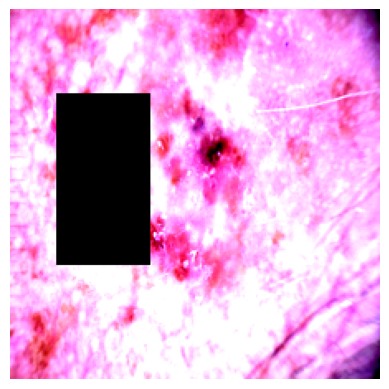

{'image_index': 0,
 'true_label': 'NV',
 'pred_label': 'NV',
 'pred_probs': array([0.36278665, 0.00992946, 0.00725848, 0.03680193, 0.00357005,
        0.31776646, 0.261887  ], dtype=float32)}

In [229]:
val_transform2 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

test_dataset2 = HAM10000Dataset(test_df, img_dirs, transform=val_transform2)

class_names = ["NV", "MEL", "BKL", "BCC", "AKIEC", "VASC", "DF"]  # Update with your class names
show_sample_prediction(ensemble_models, gating_network, train_dataset, target_class_name="NV", class_names=class_names, device=device)

In [194]:
def compute_metrics_individual(models, test_loader, device="cuda"):
    """
    Compute evaluation metrics for each individual model without gating
    
    Args:
        models: List of PyTorch models to evaluate
        test_loader: DataLoader for test data
        device: Device to run evaluation on
        
    Returns:
        Dictionary containing metrics for each model and averaged metrics
    """
    # Initialize results storage
    all_metrics = {}
    class_names = ["NV", "MEL", "BKL", "BCC", "AKIEC", "VASC", "DF"]  # Update with your class names
    
    for model_idx, model in enumerate(models):
        model.eval()
        y_true, y_pred = [], []
        y_prob = []

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                
                # Get model outputs
                outputs = model(images)
                probs = softmax(outputs, dim=1)
                
                # Store predictions
                _, predicted = torch.max(outputs, 1)
                y_true.extend(labels.cpu().numpy())
                y_pred.extend(predicted.cpu().numpy())
                y_prob.append(probs.cpu().numpy())

        # Convert to numpy arrays
        y_true = np.array(y_true)
        y_pred = np.array(y_pred)
        y_prob = np.vstack(y_prob)

        # Generate classification report
        class_report = classification_report(
            y_true, 
            y_pred, 
            output_dict=True,
            zero_division=0
        )
        
        # Extract per-class metrics
        per_class_metrics = {}
        for class_idx in range(len(class_names)):
            if str(class_idx) in class_report:
                per_class_metrics[class_names[class_idx]] = {
                    "Precision": class_report[str(class_idx)]["precision"],
                    "Recall": class_report[str(class_idx)]["recall"],
                    "F1": class_report[str(class_idx)]["f1-score"],
                    "Support": class_report[str(class_idx)]["support"]
                }

        # Calculate AUC scores
        try:
            macro_auc = roc_auc_score(y_true, y_prob, multi_class='ovr', average='macro')
            per_class_auc = {
                class_names[class_idx]: roc_auc_score(
                    (y_true == class_idx).astype(int),
                    y_prob[:, class_idx]
                )
                for class_idx in range(len(class_names))
            }
        except ValueError:
            macro_auc = None
            per_class_auc = None

        # Confusion matrix metrics
        cm = confusion_matrix(y_true, y_pred)
        per_class_acc = {
            class_names[class_idx]: cm.diagonal()[class_idx] / cm.sum(axis=1)[class_idx]
            for class_idx in range(len(class_names))
        }

        # Store model metrics
        all_metrics[f"Model_{model_idx}"] = {
            "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
            "Overall Accuracy": accuracy_score(y_true, y_pred),
            "Precision (Macro)": precision_score(y_true, y_pred, average='macro', zero_division=0),
            "Recall (Macro)": recall_score(y_true, y_pred, average='macro', zero_division=0),
            "F1 Score (Macro)": f1_score(y_true, y_pred, average='macro', zero_division=0),
            "AUC (Macro)": macro_auc,
            "Per-class Metrics": per_class_metrics,
            "Per-class AUC": per_class_auc,
            "Per-class Accuracy": per_class_acc,
            "Confusion Matrix": cm
        }
    
    # Calculate average metrics across all models
    avg_metrics = {
        "Average Balanced Accuracy": np.mean([m["Balanced Accuracy"] for m in all_metrics.values()]),
        "Average Overall Accuracy": np.mean([m["Overall Accuracy"] for m in all_metrics.values()]),
        "Average Precision (Macro)": np.mean([m["Precision (Macro)"] for m in all_metrics.values()]),
        "Average Recall (Macro)": np.mean([m["Recall (Macro)"] for m in all_metrics.values()]),
        "Average F1 Score (Macro)": np.mean([m["F1 Score (Macro)"] for m in all_metrics.values()]),
        "Average AUC (Macro)": np.mean([m["AUC (Macro)"] for m in all_metrics.values() if m["AUC (Macro)"] is not None])
    }
    
    return {
        "Individual Models": all_metrics,
        "Average Metrics": avg_metrics
    }

In [193]:
metrics = compute_metrics_ensemble(ensemble_models, final_gate, test_loader, device="cuda")
class_names = ["NV", "MEL", "BKL", "BCC", "AKIEC", "VASC", "DF"]
metrics["Per-class Metrics"] = {
    class_names[class_idx]: values 
    for class_idx, values in metrics["Per-class Metrics"].items()
}
print(metrics)

{'Balanced Accuracy': 0.7481627409455295, 'Overall Accuracy': 0.8255360623781677, 'Precision (Macro)': 0.6802337073595169, 'Recall (Macro)': 0.7481627409455295, 'F1 Score (Macro)': 0.7086403688663652, 'Per-class Metrics': {'NV': {'Precision': 0.6308724832214765, 'Recall': 0.752, 'F1': 0.6861313868613139, 'Support': 125.0}, 'MEL': {'Precision': 0.9326923076923077, 'Recall': 0.8899082568807339, 'F1': 0.9107981220657277, 'Support': 654.0}}, 'Classification Report': {'0': {'precision': 0.6308724832214765, 'recall': 0.752, 'f1-score': 0.6861313868613139, 'support': 125.0}, '1': {'precision': 0.9326923076923077, 'recall': 0.8899082568807339, 'f1-score': 0.9107981220657277, 'support': 654.0}, '2': {'precision': 0.4, 'recall': 0.5, 'f1-score': 0.4444444444444444, 'support': 8.0}, '3': {'precision': 0.5841584158415841, 'recall': 0.5462962962962963, 'f1-score': 0.5645933014354066, 'support': 108.0}, '4': {'precision': 0.7, 'recall': 1.0, 'f1-score': 0.8235294117647058, 'support': 21.0}, '5': {'p

In [195]:
metrics_ind = compute_metrics_individual(ensemble_models, test_loader)
print(metrics_ind)

{'Individual Models': {'Model_0': {'Balanced Accuracy': 0.7222571556111695, 'Overall Accuracy': 0.7992202729044834, 'Precision (Macro)': 0.6910759749964116, 'Recall (Macro)': 0.7222571556111695, 'F1 Score (Macro)': 0.7004295442680603, 'AUC (Macro)': 0.9531998657724836, 'Per-class Metrics': {'NV': {'Precision': 0.532258064516129, 'Recall': 0.792, 'F1': 0.6366559485530546, 'Support': 125.0}, 'MEL': {'Precision': 0.933993399339934, 'Recall': 0.8654434250764526, 'F1': 0.8984126984126984, 'Support': 654.0}, 'BKL': {'Precision': 0.45454545454545453, 'Recall': 0.625, 'F1': 0.5263157894736842, 'Support': 8.0}, 'BCC': {'Precision': 0.5445544554455446, 'Recall': 0.5092592592592593, 'F1': 0.5263157894736842, 'Support': 108.0}, 'AKIEC': {'Precision': 0.9047619047619048, 'Recall': 0.9047619047619048, 'F1': 0.9047619047619048, 'Support': 21.0}, 'VASC': {'Precision': 0.8095238095238095, 'Recall': 0.7183098591549296, 'F1': 0.7611940298507462, 'Support': 71.0}, 'DF': {'Precision': 0.6578947368421053, '

In [189]:
import torch
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
from torch.nn.functional import softmax

def per_class_auc_ensemble(gating_net, experts, data_loader, num_classes, device="cuda"):
    gating_net.eval()
    for expert in experts:
        expert.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            # 1️⃣ Get outputs from each expert
            expert_outputs = [expert(images) for expert in experts]  # list of (B, num_classes) logits

            # 2️⃣ Get gating weights from expert outputs
            gate_weights = gating_net(expert_outputs)  # (B, num_experts)

            # 3️⃣ Stack expert outputs into (B, num_experts, num_classes)
            outputs_stack = torch.stack(expert_outputs, dim=1)

            # 4️⃣ Weighted sum of expert outputs → final logits
            combined_logits = torch.sum(gate_weights.unsqueeze(2) * outputs_stack, dim=1)

            # 5️⃣ Convert to probabilities
            final_probs = softmax(combined_logits, dim=1)

            all_labels.append(labels.cpu().numpy())
            all_probs.append(final_probs.cpu().numpy())

    # Concatenate results
    all_labels = np.concatenate(all_labels)
    all_probs = np.concatenate(all_probs)

    # One-hot encode labels
    all_labels_bin = label_binarize(all_labels, classes=np.arange(num_classes))

    # Per-class AUC
    auc_scores = []
    for i in range(num_classes):
        try:
            auc = roc_auc_score(all_labels_bin[:, i], all_probs[:, i])
        except ValueError:
            auc = float('nan')  # Handle classes with no positive samples
        auc_scores.append(auc)

    return auc_scores


In [190]:
auc_list = per_class_auc_ensemble(final_gate, ensemble_models, test_loader, num_classes=7)
for i, auc in enumerate(auc_list):
    print(f"Class {i} AUC: {auc:.4f}")


Class 0 AUC: 0.9450
Class 1 AUC: 0.9601
Class 2 AUC: 0.9910
Class 3 AUC: 0.9058
Class 4 AUC: 0.9991
Class 5 AUC: 0.9881
Class 6 AUC: 0.9733


In [177]:
bacc = compute_bacc(ensemble_models, final_gate, test_loader, device=device)
print(bacc)

0.7481627409455295


In [183]:
metrics = compute_metrics_ensemble(ensemble_models, final_gate, test_loader)
print(metrics)

{'Balanced Accuracy': 0.7481627409455295, 'Overall Accuracy': 0.8255360623781677, 'Precision (Macro)': 0.6802337073595169, 'Recall (Macro)': 0.7481627409455295, 'F1 Score (Macro)': 0.7086403688663652, 'AUC (Macro)': 0.9663551333667915, 'Per-class Accuracy': array([0.752     , 0.88990826, 0.5       , 0.5462963 , 1.        ,
       0.83098592, 0.71794872])}


In [116]:
train_dataset_fusion = HAM10000FusionDataset(train_df, img_dirs, transform=train_transform)
val_dataset_fusion = HAM10000FusionDataset(val_df, img_dirs, transform=val_transform)
test_dataset_fusion = HAM10000FusionDataset(test_df, img_dirs, transform=val_transform)

train_loader_fusion = DataLoader(
    train_dataset_fusion,
    batch_size=64,
    shuffle=True
)
val_loader_fusion = DataLoader(val_dataset_fusion, batch_size=64, shuffle=False)
test_loader_fusion = DataLoader(test_dataset_fusion, batch_size=64, shuffle=False)

# train_dataset = HAM10000Dataset(train_df, img_dirs, transform=train_transform)
# val_dataset = HAM10000Dataset(val_df, img_dirs, transform=val_transform)
# test_dataset = HAM10000Dataset(test_df, img_dirs, transform=val_transform)

# label_counts = train_df['label'].value_counts().sort_index().values
# class_weights = 1. / label_counts
# class_weights = class_weights / class_weights.sum() * len(class_weights)  # Normalize

# label_to_weight = {label: class_weights[i] for i, label in enumerate(sorted(train_df['label'].unique()))}
# sample_weights = train_df['label'].map(label_to_weight).values

# sampler = WeightedRandomSampler(
#     weights=sample_weights,
#     num_samples=len(sample_weights),
#     replacement=True
# )

# train_loader = DataLoader(
#     train_dataset,
#     batch_size=64,
#     shuffle=True
# )
# val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
# test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [141]:
import torch.nn.functional as F

class GatedEnsembleWithMetadata(nn.Module):
    def __init__(self, models, gating_network, meta_input_dim=meta_input_dim, num_classes=7):
        super(GatedEnsembleWithMetadata, self).__init__()
        self.models = models  # ensemble of trained models
        self.gating_network = gating_network # trained gating net
        self.num_classes = num_classes

        self.meta_net = nn.Sequential(
            nn.Linear(meta_input_dim, 32),  # Reduced from 64
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.3),  # Reduced dropout
            nn.Linear(32, 16),  # Reduced from 32
            nn.BatchNorm1d(16),
            nn.ReLU(),
            nn.Dropout(0.3)
        )

        # Weighting parameters
        self.ensemble_weight = nn.Parameter(torch.tensor(2.0))  # Trainable weight
        self.meta_weight = nn.Parameter(torch.tensor(1.0))  # Trainable weight

        # Final classifier
        self.classifier = nn.Sequential(
            nn.Linear(num_classes + 16, 64),  # Reduced size
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

        # Freeze gating network if you don't want to retrain it
        for param in self.gating_network.parameters():
            param.requires_grad = False

    def forward(self, image, metadata):
        # Get ensemble outputs
        model_outputs = [model(image) for model in self.models]
        
        # Get gating weights
        gate_weights = self.gating_network(model_outputs)
        
        # Stack and weight outputs
        model_outputs_stack = torch.stack(model_outputs, dim=1)
        weighted_output = torch.sum(gate_weights.unsqueeze(2) * model_outputs_stack, dim=1)
        
        # Process metadata (outputs 16-dim features)
        meta_features = self.meta_net(metadata)
        
        # Apply learned weights to balance contributions
        scaled_ensemble = weighted_output * self.ensemble_weight
        scaled_meta = meta_features * self.meta_weight
        
        # Concatenate features (num_classes + 16)
        combined = torch.cat([scaled_ensemble, scaled_meta], dim=1)
        
        # Final classification
        output = self.classifier(combined)
        
        return output
        


In [139]:
def train_model_bacc_meta(model, train_loader, val_loader, criterion, num_epochs, learning_rate, weight_decay, device, checkpoint_path):
    model = model.to(device)
    best_val_acc = 0.0
    best_model_wts = model.state_dict()

    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=learning_rate, weight_decay=weight_decay)

    scheduler = MultiStepLR(optimizer, milestones=[10, 20, 30], gamma=0.1)

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")

        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        y_true_train, y_pred_train = [], []

        for images, metadata, labels in tqdm(train_loader, desc="Training"):
            images, metadata, labels = images.to(device), metadata.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images, metadata)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend(preds.cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
        print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        y_true_val, y_pred_val = [], []

        with torch.no_grad():
            for images, metadata, labels in tqdm(val_loader, desc="Validation"):
                images, metadata, labels = images.to(device), metadata.to(device), labels.to(device)
                outputs = model(images, metadata)
                loss = criterion(outputs, labels)
                val_loss += loss.item()

                _, preds = torch.max(outputs, 1)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend(preds.cpu().numpy())

        val_loss /= len(val_loader)
        val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)

        if val_bacc > best_val_acc:
            best_val_acc = val_bacc
            best_model_wts = model.state_dict()
            print("Best model updated")

            torch.save({
                'epoch': epoch + 1,
                'model_state_dict': best_model_wts,
                'optimizer_state_dict': optimizer.state_dict(),
                'val_acc': best_val_acc
            }, checkpoint_path)

        print(f"Val Loss: {val_loss:.4f}, Val BACC: {val_bacc:.4f}")

        # Step scheduler at the end of each epoch
        scheduler.step()

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model


In [143]:
metadata_model = GatedEnsembleWithMetadata(ensemble_models, final_gate)
metadata_path = "C:/Users/sabad/OneDrive/Desktop/APS360/HAM10K Dataset/Final Model/Final Weights/final_weights.pth"
metadata_model = train_model_bacc_meta(metadata_model, train_loader_fusion, val_loader_fusion, criterion=criterion_weighted, num_epochs=30, learning_rate=1e-4, weight_decay=1e-5, device=device, checkpoint_path=metadata_path)


Epoch 1/30


Training: 100%|██████████| 125/125 [01:00<00:00,  2.08it/s]


Train Loss: 1.8547, Train BACC: 0.2340


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.35it/s]


Best model updated
Val Loss: 1.9061, Val BACC: 0.3071

Epoch 2/30


...

Train Loss: 0.6514, Train BACC: 0.8402


Validation: 100%|██████████| 16/16 [00:09<00:00,  1.66it/s]


Val Loss: 1.5701, Val BACC: 0.4273

Epoch 16/30


Training:   0%|          | 0/125 [00:00<?, ?it/s]


KeyboardInterrupt: 

**Train Gated Ensemble**

In [ ]:


criterion = torch.nn.CrossEntropyLoss()

num_epochs = 10
for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    for model in ensemble_models:
        model.eval()
    gating_network.train()
    
    running_loss = 0.0
    y_true_train, y_pred_train = [], []

    # --- TRAIN ---
    for images, labels in tqdm(train_loader, desc="Training"):
        images, labels = images.to(device), labels.to(device)

        with torch.no_grad():
            outputs = [model(images).to(device) for model in ensemble_models]

        weights = gating_network(outputs)  # [B, N_models]
        outputs_stack = torch.stack(outputs, dim=1)  # [B, N_models, num_classes]

        # Top-k selection
        topk_vals, topk_indices = torch.topk(weights, k=1, dim=1)
        topk_weights = softmax(topk_vals, dim=1)

        B, N_models, num_classes = outputs_stack.size()
        batch_indices = torch.arange(B, device=device).unsqueeze(1).expand(-1, 2)
        topk_outputs = outputs_stack[batch_indices, topk_indices]

        combined_output = torch.sum(topk_weights.unsqueeze(2) * topk_outputs, dim=1)

        loss = criterion(combined_output, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(combined_output, 1)
        y_true_train.extend(labels.cpu().numpy())
        y_pred_train.extend(predicted.cpu().numpy())

    train_loss = running_loss / len(train_loader)
    train_bacc = balanced_accuracy_score(y_true_train, y_pred_train)
    print(f"Train Loss: {train_loss:.4f}, Train BACC: {train_bacc:.4f}")

    # --- VALIDATION ---
    for model in ensemble_models:
        model.eval()
    gating_network.eval()

    val_loss = 0.0
    y_true_val, y_pred_val = [], []

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc="Validation"):
            images, labels = images.to(device), labels.to(device)
            outputs = [model(images).to(device) for model in ensemble_models]

            weights = gating_network(outputs)
            outputs_stack = torch.stack(outputs, dim=1)
            weights = softmax(weights, dim=1)

            topk_vals, topk_indices = torch.topk(weights, k=1, dim=1)
            topk_weights = softmax(topk_vals, dim=1)

            B, N_models, num_classes = outputs_stack.size()
            batch_indices = torch.arange(B, device=device).unsqueeze(1).expand(-1, 2)
            topk_outputs = outputs_stack[batch_indices, topk_indices]

            combined_output = torch.sum(topk_weights.unsqueeze(2) * topk_outputs, dim=1)

            loss = criterion(combined_output, labels)
            val_loss += loss.item()

            _, predicted = torch.max(combined_output, 1)
            y_true_val.extend(labels.cpu().numpy())
            y_pred_val.extend(predicted.cpu().numpy())

    avg_val_loss = val_loss / len(val_loader)
    val_bacc = balanced_accuracy_score(y_true_val, y_pred_val)
    print(f"Val Loss: {avg_val_loss:.4f}, Val BACC: {val_bacc:.4f}")


Epoch 1/10


Training: 100%|██████████| 125/125 [01:04<00:00,  1.93it/s]


Train Loss: 0.7964, Train BACC: 0.8163


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.44it/s]


Val Loss: 0.9036, Val BACC: 0.7893

Epoch 2/10


...

Val Loss: 0.9036, Val BACC: 0.7893

Epoch 10/10


Training: 100%|██████████| 125/125 [01:00<00:00,  2.08it/s]


Train Loss: 0.7949, Train BACC: 0.8110


Validation: 100%|██████████| 16/16 [00:06<00:00,  2.45it/s]

Val Loss: 0.9036, Val BACC: 0.7893
